# Project week 7

For the project this week, you are given a video of a ball rolling over a surface. Your job is now to detect the ball, track the position, velocity and acceleration using a Kalman filter, and finally draw the currently tracked position and predicted position of the ball in the images, while also printing the whole predicted state in either the image or the terminal.

The video "rolling_ball_result.mp4" shows what the end result could look like.

You have to make the Kalman filter yourselves, i.e. initialize the matrices and make a update and predict function. You are of course allowed to use numpy.

You can use the code below and fill in the missing parts.



## 1: Detecting the ball

`HoughCircles` on the grayscale frame misses most frames, since the ball is motion blurred and does not stand out much from the grey wall. So we first make a colour mask with HSV thresholds and then run `HoughCircles` on the mask, where the ball is a clean white disc. Red needs two hue ranges, since red wraps around 0 and 180 in OpenCV's hue scale.

The red range asks for high saturation and not too bright pixels, otherwise the shadowed tape on the box and the hand in the challenge video are also picked up as red. We keep only the strongest circle, with a radius of at least 50 px (the balls are 70 to 90 px), so tiny circles and a ball that is half hidden behind the box are ignored and the filter predicts instead.


In [22]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# HSV ranges per ball colour, yellow and blue are only needed for the challenge
COLOUR_RANGES = {
    'red': [((0, 150, 50), (8, 255, 180)), ((170, 150, 50), (180, 255, 180))],
    'yellow': [((20, 100, 100), (35, 255, 255))],
    'blue': [((85, 80, 20), (110, 255, 200))],
}


def detect_ball(frame, colour):
    """Return (x, y, radius) of the ball with this colour, or None if it is not visible."""
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    mask = np.zeros(hsv.shape[:2], np.uint8)
    for lower, upper in COLOUR_RANGES[colour]:
        mask |= cv2.inRange(hsv, lower, upper)

    # Remove small specks, then blur so the disc has smooth edges for the gradient-based Hough
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    mask = cv2.GaussianBlur(mask, (9, 9), 2)

    circles = cv2.HoughCircles(mask, cv2.HOUGH_GRADIENT, dp=2, minDist=200,
                               param1=100, param2=30, minRadius=50, maxRadius=90)
    if circles is None:
        return None
    return circles[0][0]

In [23]:
# In which frames do we find the ball?
cap = cv2.VideoCapture('rolling_ball.mp4')
found = []
frame_idx = 0
while True:
    ret, frame = cap.read()
    if not ret:
        break
    if detect_ball(frame, 'red') is not None:
        found.append(frame_idx)
    frame_idx += 1
cap.release()

print(f'{frame_idx} frames, ball detected in {len(found)} of them:')
print(found)

66 frames, ball detected in 27 of them:
[16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52]


The ball enters from the right around frame 16, is detected until frame 32, disappears behind the box, and is detected again from frame 43 until it leaves on the left. The frames in between are the occlusion, where the Kalman filter has to predict without any measurement.


## 2: The Kalman filter

We track position, velocity and acceleration in both x and y, so there are 6 state variables and the state vector is 6x1:

$$x = [p_x, v_x, a_x, p_y, v_y, a_y]^T$$

With $\Delta t = 1$ (one frame), constant acceleration gives

$$p_{new} = p + v + \tfrac{1}{2}a, \quad v_{new} = v + a, \quad a_{new} = a$$

which is the 3x3 block in `F`, used once for x and once for y. The detector only gives us the position, so `H` picks out $p_x$ and $p_y$. Units are pixels and frames, so velocity is in pixels per frame.

We also added process noise `Q` to the prediction step, $P = FPF^T + Q$. Without it the filter quickly becomes too sure of its own model and stops listening to the measurements. We tried it: the prediction error grew to around 130 px while the ball was clearly visible, and during the occlusion it predicted the ball far off the left edge of the image. With `Q = I` the prediction error drops to a few pixels.


In [24]:
def update(x, P, Z, H, R):
    y = Z - H @ x                      # innovation, 2x1
    S = H @ P @ H.T + R                # innovation covariance, 2x2
    K = P @ H.T @ np.linalg.pinv(S)    # Kalman gain, 6x2
    x = x + K @ y
    P = (np.eye(len(x)) - K @ H) @ P
    return x, P


def predict(x, P, F, u, Q):
    x = F @ x + u
    P = F @ P @ F.T + Q
    return x, P


# Initialize Kalman filter
# State order: [x, vx, ax, y, vy, ay]
# The initial state (6x1). Replaced by the first detection when a track starts
x = np.zeros((6, 1))

# The initial uncertainty (6x6). We know nothing about velocity and acceleration yet
P = np.eye(6) * 1000

# The external motion (6x1)
u = np.zeros((6, 1))

# The transition matrix (6x6). The same constant-acceleration block for x and for y, dt = 1 frame
dt = 1
block = np.array([[1, dt, 0.5 * dt**2],
                  [0, 1,  dt],
                  [0, 0,  1]])
F = np.block([[block, np.zeros((3, 3))],
              [np.zeros((3, 3)), block]])

# The observation matrix (2x6). We only measure the positions
H = np.array([[1, 0, 0, 0, 0, 0],
              [0, 0, 0, 1, 0, 0]])

# The measurement uncertainty (2x2), roughly 5 px standard deviation
R = np.eye(2) * 25

# The process noise (6x6), see the explanation above
Q = np.eye(6) * 1

### Checking the matrix sizes


In [25]:
z = np.zeros((2, 1))
S = H @ P @ H.T + R
K = P @ H.T @ np.linalg.pinv(S)

for name, m in [('x', x), ('P', P), ('F', F), ('Q', Q), ('u', u),
                ('z', z), ('H', H), ('R', R), ('S', S), ('K', K)]:
    print(f'{name}: {m.shape}')

# Every product in update and predict must give back the shape it replaces
assert (F @ x + u).shape == x.shape and (F @ P @ F.T + Q).shape == P.shape
assert (z - H @ x).shape == z.shape and (x + K @ (z - H @ x)).shape == x.shape
assert ((np.eye(6) - K @ H) @ P).shape == P.shape
print('All matrix operations have consistent sizes.')

x: (6, 1)
P: (6, 6)
F: (6, 6)
Q: (6, 6)
u: (6, 1)
z: (2, 1)
H: (2, 6)
R: (2, 2)
S: (2, 2)
K: (6, 2)
All matrix operations have consistent sizes.


## 3: Tracking the ball

Every frame we detect the ball, update the filter if it was found, and then always predict the next state. While the ball is behind the box there is no measurement, so only predict is used.

A track starts at the first detection, with the position taken from the detection, velocity and acceleration set to zero, and a large `P`. A track is dropped when its prediction leaves the image, or when the ball has not been seen for 12 frames (the occlusion behind the box is about 10 frames).

We also gate the measurements: if a detection is more than 200 px from where the filter predicted the ball, it is not fused into the track. Instead a new track is started at the detection. Without this, a wrong detection or a ball that is rolled in again from somewhere else gets pulled into the old track, and the velocity estimate shoots up to thousands of pixels per frame.

The same function works for one or several balls, it simply runs one Kalman filter per colour, which we use again for the challenge.

In the output, the green circle is the current estimate and the blue circle is the prediction for the next frame, and the predicted state is written on the image. We save the result as a video instead of using `cv2.imshow`, since OpenCV windows opened from a notebook tend to freeze or crash on Mac. The video is saved at a third of the original frame rate (`slow_down=3`), so it plays 3 times slower and is easier to follow.


In [26]:
DRAW = {'current': (0, 200, 0), 'prediction': (255, 0, 0)}   # BGR


def track_video(video_path, output_path, colours, max_missed=12, gate=200, slow_down=3, snapshot_frames=()):
    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)) // 2
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)) // 2
    # The output is written at a lower frame rate so it plays slower and is easier to check
    out = cv2.VideoWriter(output_path, cv2.VideoWriter_fourcc(*'avc1'), fps / slow_down, (width, height))

    tracks = {colour: None for colour in colours}
    r_margin = 80      # allow the centre to be slightly outside while the ball is at the edge
    errors = []        # distance between the predicted position and the next detection
    snapshots = {}
    frame_idx = 0

    # Looping through all the frames
    while True:
        ret, frame = cap.read()
        if not ret:
            break

        for line, colour in enumerate(colours):
            # Detect the ball
            detection = detect_ball(frame, colour)
            track = tracks[colour]

            # Gating: a detection far from the prediction starts a new track instead of updating this one
            if detection is not None and track is not None:
                z = np.array([[detection[0]], [detection[1]]])
                if np.linalg.norm(H @ track['x'] - z) > gate:
                    track = tracks[colour] = None

            if detection is not None and track is None:
                x0 = x.copy()
                x0[0], x0[3] = detection[0], detection[1]
                track = tracks[colour] = {'x': x0, 'P': P.copy(), 'missed': 0, 'radius': detection[2]}
            if track is None:
                continue

            # If the ball is found, update the Kalman filter
            if detection is not None:
                z = np.array([[detection[0]], [detection[1]]])
                errors.append(float(np.linalg.norm(H @ track['x'] - z)))
                track['x'], track['P'] = update(track['x'], track['P'], z, H, R)
                track['missed'] = 0
                track['radius'] = detection[2]
            else:
                track['missed'] += 1
                if track['missed'] > max_missed:
                    tracks[colour] = None
                    continue

            # Predict the next state
            current = track['x'].copy()
            track['x'], track['P'] = predict(track['x'], track['P'], F, u, Q)
            pred = track['x']

            # Drop the track once the ball is predicted to be outside the image
            full_w, full_h = width * 2, height * 2
            if not (-r_margin < pred[0, 0] < full_w + r_margin and -r_margin < pred[3, 0] < full_h + r_margin):
                tracks[colour] = None

            # Draw the current tracked state and the predicted state on the image frame ###
            r = int(track['radius'])
            cx, cy = int(current[0, 0]), int(current[3, 0])
            px, py = int(pred[0, 0]), int(pred[3, 0])
            label = colour if detection is not None else f'{colour} (no detection)'
            cv2.circle(frame, (cx, cy), r, DRAW['current'], 6)
            cv2.putText(frame, label, (cx + r, cy - r), cv2.FONT_HERSHEY_SIMPLEX, 1.5, DRAW['current'], 3)
            cv2.circle(frame, (px, py), r, DRAW['prediction'], 6)

            # Predicted state as text, one line per ball
            text = (f'{colour}  pos ({pred[0, 0]:.0f}, {pred[3, 0]:.0f})  '
                    f'vel ({pred[1, 0]:.1f}, {pred[4, 0]:.1f})  acc ({pred[2, 0]:.2f}, {pred[5, 0]:.2f})')
            cv2.putText(frame, text, (40, 70 + 60 * line), cv2.FONT_HERSHEY_SIMPLEX, 1.6, (0, 0, 0), 4)

        cv2.putText(frame, f'frame {frame_idx}', (40, height * 2 - 40), cv2.FONT_HERSHEY_SIMPLEX, 1.6, (0, 0, 0), 4)
        # Write the frame to the output video (instead of cv2.imshow)
        small = cv2.resize(frame, (width, height))
        out.write(small)
        if frame_idx in snapshot_frames:
            snapshots[frame_idx] = cv2.cvtColor(small, cv2.COLOR_BGR2RGB)
        frame_idx += 1

    cap.release()
    out.release()
    return snapshots, errors


def show_snapshots(snapshots, cols=3):
    rows = int(np.ceil(len(snapshots) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 3.6 * rows))
    for ax in np.ravel(axes):
        ax.axis('off')
    for ax, (idx, img) in zip(np.ravel(axes), snapshots.items()):
        ax.imshow(img)
        ax.set_title(f'frame {idx}')
    plt.tight_layout()
    plt.show()

Mean prediction error while the ball is visible: 14.6 px
Prediction error when the ball comes out from behind the box (frame 43): 70.4 px


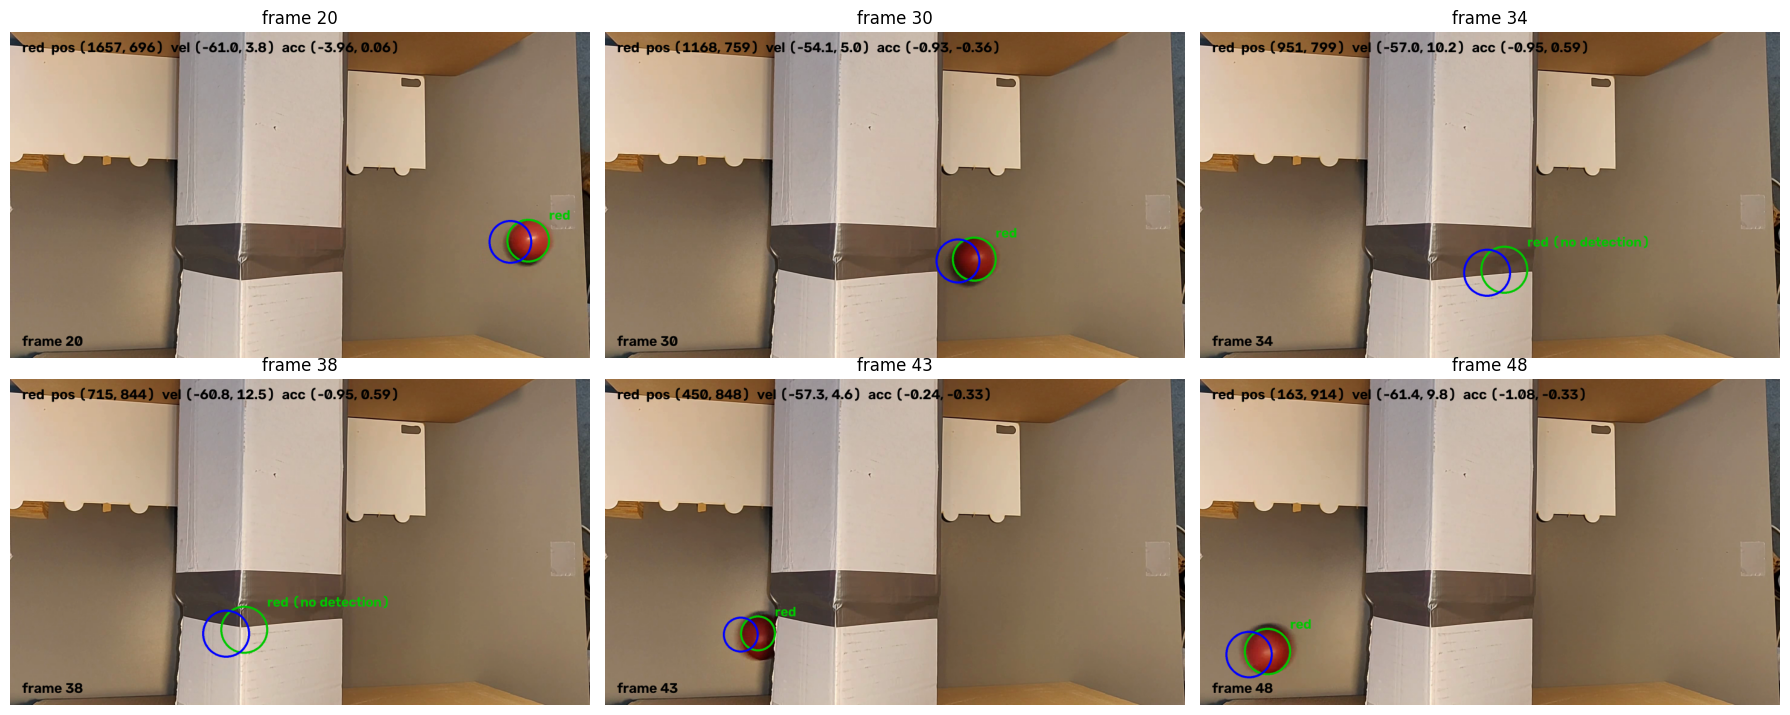

In [27]:
snapshots, errors = track_video('rolling_ball.mp4', 'tracked_ball.mp4', ['red'],
                                snapshot_frames=(20, 30, 34, 38, 43, 48))

# errors[0] is the very first detection of the track, so it is skipped
print(f'Mean prediction error while the ball is visible: {np.mean(errors[1:]):.1f} px')

# The first detection after a gap in the detected frames is where the ball comes out from behind the box
reappear = next(i for i in range(1, len(found)) if found[i] - found[i - 1] > 1)
print(f'Prediction error when the ball comes out from behind the box (frame {found[reappear]}): {errors[reappear]:.1f} px')
show_snapshots(snapshots)

The filter locks onto the ball within a few frames, after that the blue prediction sits almost on top of the green estimate. Behind the box (frames 34 and 38) there is no detection, so the filter only predicts and the circle keeps moving along the path the ball was on. When the ball comes out on the other side, the prediction is off by about 70 px, which is not bad given that it was predicting blind for about 10 frames. The full result is saved in `tracked_ball.mp4`.


## Hints

The first part is to detect the ball. For this part you can look back to the exercises from week 2. More specifically the end of exercise 1. You may have to adjust some parameters in order to only detect the ball.

The next part is to make the Kalman filter. If you did the exercises from monday this week, you already have a suitable update and predict function. You will have to initialize all the different matrices, which we also did in the exercises, however this time we would like the state to include position, velocity and acceleration in both the x- and y-direction (6 states).

Start by defining your state **x** and uncertainty **P**. Then define a transition matrix **F** based on your state. When defining the state transition last time we used the equation for linear motion:

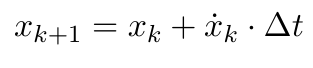

We used dt = 1 (delta t), for simplicity. You can do the same here. However, this time we also have the acceleration and therefore we use:

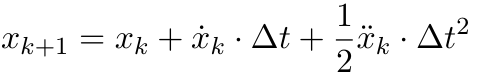

Finally, for a part of the video, the ball is behind something and can't be seen. Obviously we cant update our state here, because there is no measurement. So when there is no measurements available, you should only use the predict function and not the update function, to estimate the state.


# Challenge

If you can't get enough of tracking and Kalman filters, try extending your program, such that it can keep track of multiple balls at the same time. Use the video "rolling_ball_challenge.mp4" to test it. You can take advantage of the balls having different colours.

The challenge video has a red and a yellow ball that are rolled across the scene several times, sometimes at the same time, and once there is also a dark blue ball. We give each ball its own Kalman filter and tell them apart by colour, so detection and the filter are exactly the same as above, just run once per colour. A track is dropped when its ball leaves the image and a new one starts the next time it is seen.


Median prediction error over all detections: 9.7 px


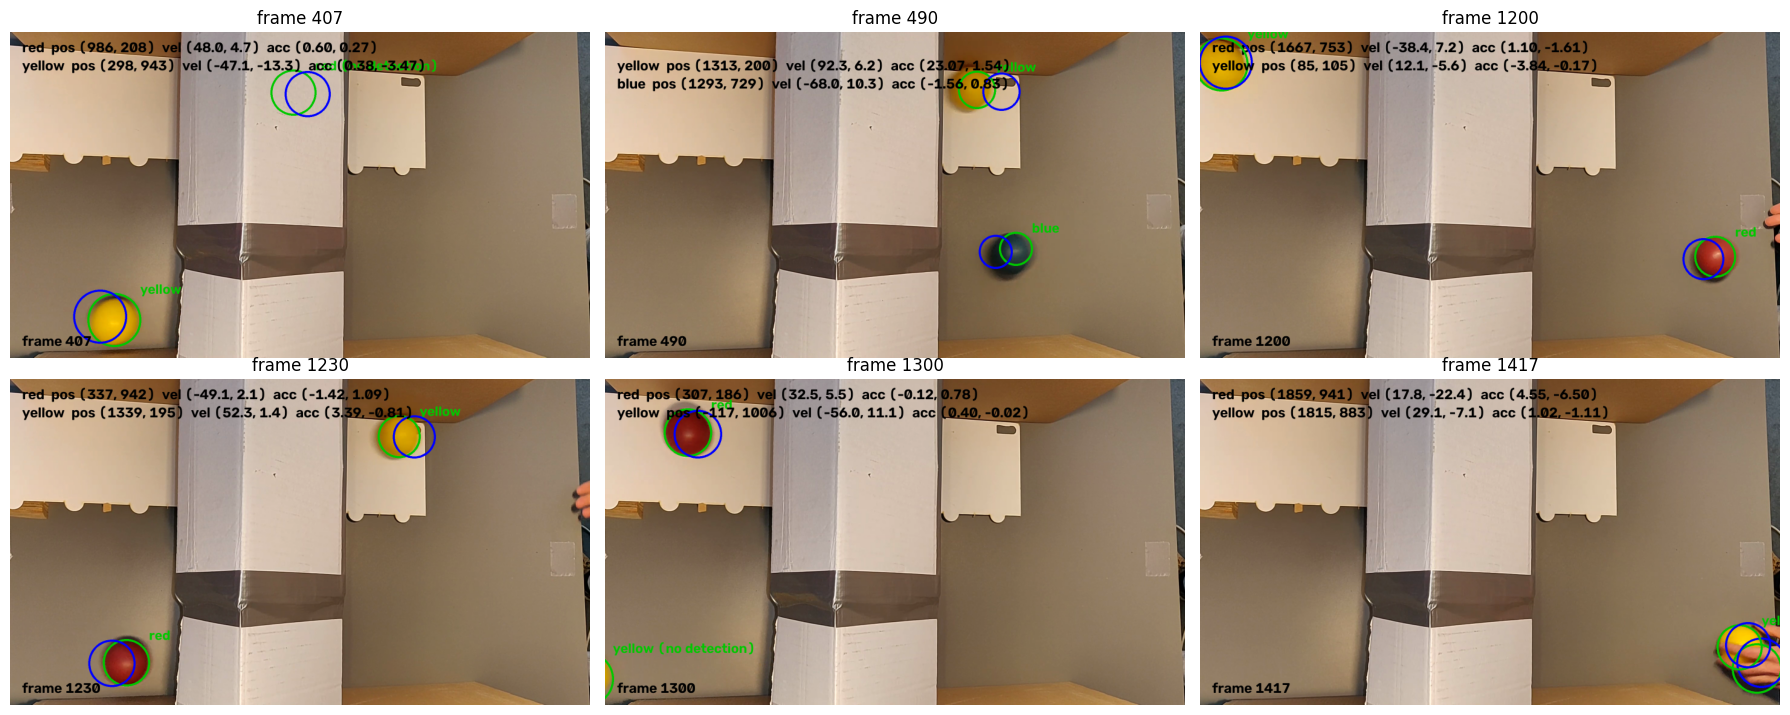

In [28]:
snapshots_ch, errors_ch = track_video('rolling_ball_challenge.mp4', 'tracked_balls_challenge.mp4', ['red', 'yellow', 'blue'],
                                      snapshot_frames=(407, 490, 1200, 1230, 1300, 1417))

print(f'Median prediction error over all detections: {np.median(errors_ch):.1f} px')
show_snapshots(snapshots_ch)

All three balls are tracked, and since each colour has its own filter they never get mixed up. When a ball goes behind the box, its filter keeps predicting and picks it up again on the other side (frame 407). The blue ball only passes once, around frame 490.

The tighter red range and the gating fixed most of the problems in this video, but the hand pushing the balls is still sometimes detected as the red ball (frame 1417). With identical balls we could not use colour, so we would have to match each detection to the closest prediction instead. The full result is saved in `tracked_balls_challenge.mp4`.


Note: We used generative AI to help with the code and comments.